# 07. Контраст: 2D квадратная решётка — провал

**Проект «Структура и Данные»** — Notebook 07

## Зачем этот ноутбук

В notebook 06 мы показали: **honeycomb** решётка даёт точный 2D Дирак с **2 компонентами** ($|f(K)| = 4.4\times 10^{-16}$, $\alpha = 1.01$, изотропия 1.0000).

Этот ноутбук — **контраст**: квадратная решётка **не работает**, независимо от числа компонент и оптимизации. Это **важный** отрицательный результат: он показывает, что **правильная геометрия критична**, а не число компонент.

## Что проверяется

1. **4 компоненты, осевые сдвиги:** gauge-инвариантность, но дисперсия анизотропна
2. **8 компонент, диагональные сдвиги:** всё ещё анизотропия
3. **Структурный C4-инвариантный coin:** даёт **плоскую зону** (изотропию без дисперсии — не Дирак)
4. **Dirac-fit оптимизация:** MSE $\sim 10^{-4}$ (приблизительный, но не точный)
5. **Случайный поиск 200 монет:** статистика показывает, что случайный поиск не работает

## Физическая причина провала

На **квадратной** решётке с **осевыми** сдвигами сдвиг $S(k) = \text{diag}(e^{-ik_x}, e^{ik_y}, e^{ik_x}, e^{ik_y})$ **диагонален**. Кинетические члены $k_x$ и $k_y$ **не смешиваются**. Это даёт **две независимые 1D Дирака**, а не один 2D. Отсюда анизотропия.

На **honeycomb** решётке (06) две подрешётки A, B + три направления под 120° дают **естественное** смешивание $k_x, k_y$. Это работает с 2 компонентами.

## Гипотеза и её провал

**Наивная гипотеза:** если увеличить число компонент, изотропия восстановится.

**Реальность:** **нет**. Даже 8 компонент на квадратной решётке дают ratio $> 1.1$. Это **структурное** ограничение квадратной решётки (аналог теоремы Нильсена-Ниномии), а не недостаток компонент.

## Ожидаемые результаты (из статьи §7.2)

| Тест | Результат |
|---|---|
| 4-comp, axis shifts | ratio $\approx 1.58$ |
| 8-comp, diagonal shifts | ratio $\approx 1.14$ |
| C4-invariant (структурный) | изотропия 1.0, **но** плоская зона (не Дирак) |
| Dirac-fit (MSE) | $\sim 2\times 10^{-4}$ (не $< 10^{-6}$) |
| Случайный поиск (200 монет) | min MSE $> 0.1$ |
| **Контраст с honeycomb** | $\|f(K)\| = 4.4 \times 10^{-16}$ |

## Что это доказывает

**Правильная геометрия важнее числа компонент.** 2 компоненты на honeycomb работают точно. 8 компонент на квадратной — нет. Это **фальсифицирует** наивный паттерн $N = 2^{d+1}$ и показывает, что компонентность — не главное.

## Связь со статьёй

- **§7.1**: 2D honeycomb (позитивный результат)
- **§7.2**: «3D s-орбитальные решётки не поддерживают Дирак» (аналогичная проблема)
- **§10.4**: «Геометрия важнее числа компонент»

## Параметры запуска

- `L = 32` (для трансфер-матрицы в k-пространстве — не критично)
- `mass = 0.1`
- 16 углов для изотропии, $|k| = 0.1$
- 200 случайных унитарных монет для статистики

## Время выполнения

- **< 30 секунд** на Colab

## Что будет сгенерировано

- **Рисунок** `07_2d_square_fail.png` — две панели:
  - **Левая:** дисперсия по направлениям на квадратной решётке (анизотропия видна)
  - **Правая:** сравнение с honeycomb (2 комп.) — резкий контраст

---

**Файл:** `notebooks/07_2d_square_fail.ipynb`  
**Предыдущий:** `06_2d_honeycomb.ipynb`  
**Следующий:** `08_3d_domain_wall.ipynb`  
**Репозиторий:** `github.com/<username>/qca-structure-data`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, eigvals
from scipy.optimize import minimize

print(f"numpy version: {np.__version__}")

# ============================================================
# Сдвиги для квадратной решётки
# ============================================================
# 4-компонентный: R(+x), L(-x), U(+y), D(-y)
shifts_4_axis = np.array([[1,0], [-1,0], [0,1], [0,-1]], dtype=float)

# 8-компонентный: 4 осевых + 4 диагональных
shifts_8_axis_diag = np.array([
    [1,0], [0,1], [-1,0], [0,-1],
    [1,1], [1,-1], [-1,1], [-1,-1]
], dtype=float)

def transfer_matrix(kx, ky, shifts, coin):
    """M(k) = diag(e^{-i k·d_a}) · C."""
    phases = np.array([np.exp(-1j*(d[0]*kx + d[1]*ky)) for d in shifts])
    return np.diag(phases) @ coin

def dispersion(kx, ky, shifts, coin):
    """Минимальная положительная частота ω(k)."""
    M = transfer_matrix(kx, ky, shifts, coin)
    eigs = np.linalg.eigvals(M)
    return np.abs(np.angle(eigs)).min()

def anisotropy_ratio(coin, shifts, k_mag=0.1, n_angles=16):
    """ratio = max ω / min ω по направлениям."""
    omegas = []
    for theta in np.linspace(0, 2*np.pi, n_angles, endpoint=False):
        kx, ky = k_mag*np.cos(theta), k_mag*np.sin(theta)
        omegas.append(dispersion(kx, ky, shifts, coin))
    return max(omegas) / min(omegas)

# ============================================================
# SU(N) генераторы (для оптимизации)
# ============================================================
def su_generators(n):
    gens = []
    # Off-diagonal symmetric
    for i in range(n):
        for j in range(i+1, n):
            g = np.zeros((n,n), dtype=complex)
            g[i,j] = g[j,i] = 1
            gens.append(g)
    # Off-diagonal antisymmetric
    for i in range(n):
        for j in range(i+1, n):
            g = np.zeros((n,n), dtype=complex)
            g[i,j] = -1j; g[j,i] = 1j
            gens.append(g)
    # Diagonal (Cartan)
    for k in range(1, n):
        g = np.zeros((n,n), dtype=complex)
        for i in range(k):
            g[i,i] = 1
        g[k,k] = -k
        gens.append(g / np.sqrt(k*(k+1)))
    return gens

def make_coin_from_params(params, gens):
    """coin = exp(-i Σ θ_a G_a)."""
    H = np.zeros(gens[0].shape, dtype=complex)
    for p, g in zip(params, gens):
        H += p * g
    return expm(-1j * H)

# ============================================================
# Случайная унитарная матрица
# ============================================================
def random_unitary(n, seed):
    np.random.seed(seed)
    A = np.random.randn(n, n) + 1j*np.random.randn(n, n)
    Q, _ = np.linalg.qr(A)
    return Q

print("Functions ready.")
print(f"4-comp shifts: {len(shifts_4_axis)}")
print(f"8-comp shifts: {len(shifts_8_axis_diag)}")

numpy version: 2.4.6
Functions ready.
4-comp shifts: 4
8-comp shifts: 8


In [3]:
# ============================================================
# Правильный coin: R↔L и U↔D отдельно (блочно-диагональный)
# ============================================================
m_coin = 0.2
c, s = np.cos(m_coin), np.sin(m_coin)

C_RL = np.array([[c, -1j*s], [-1j*s, c]], dtype=complex)
C4 = np.zeros((4, 4), dtype=complex)
C4[0:2, 0:2] = C_RL   # R↔L
C4[2:4, 2:4] = C_RL   # U↔D

print("=" * 65)
print("ТЕСТ 1: 4-comp, axis shifts (R, L, U, D)")
print("=" * 65)

ratio_4 = anisotropy_ratio(C4, shifts_4_axis, k_mag=0.3)
print(f"Anisotropy ratio (max ω / min ω): {ratio_4:.4f}")
print(f"Status: {'❌ ANISOTROPIC' if ratio_4 > 1.05 else '✅ isotropic'}")

print(f"\n{'θ (deg)':>8} {'ω(k=0.3)':>12}")
print('-' * 25)
for theta_deg in [0, 15, 30, 45, 60, 75, 90]:
    theta = np.deg2rad(theta_deg)
    w = dispersion(0.3*np.cos(theta), 0.3*np.sin(theta), shifts_4_axis, C4)
    print(f"{theta_deg:>8} {w:>12.6f}")

ТЕСТ 1: 4-comp, axis shifts (R, L, U, D)
Anisotropy ratio (max ω / min ω): 1.4526
Status: ❌ ANISOTROPIC

 θ (deg)     ω(k=0.3)
-------------------------
       0     0.200000
      15     0.214355
      30     0.249397
      45     0.290511
      60     0.249397
      75     0.214355
      90     0.200000


In [5]:
# ============================================================
# 8-comp: правильно спаренные противоположные направления
# ============================================================
# shifts: [E, N, W, S, NE, SE, NW, SW]
#         0   1   2   3   4   5   6   7
# Противоположные: (E, W)=(0,2), (N, S)=(1,3), (NE, SW)=(4,7), (SE, NW)=(5,6)
K8 = np.zeros((8,8), dtype=complex)
pairs_correct = [(0,2), (1,3), (4,7), (5,6)]  # ✅ исправлено
for i, j in pairs_correct:
    K8[i,j] = 1
    K8[j,i] = 1

C8 = expm(-1j * m_coin * K8)

print("=" * 65)
print("ТЕСТ 2: 8-comp, axis + diagonal shifts")
print("=" * 65)

ratio_8 = anisotropy_ratio(C8, shifts_8_axis_diag, k_mag=0.3)
print(f"Anisotropy ratio: {ratio_8:.4f}")
print(f"Status: {'❌ ANISOTROPIC' if ratio_8 > 1.05 else '⚠️ isotropic?'}")

print(f"\n{'θ (deg)':>8} {'ω(k=0.3)':>12}")
print('-' * 25)
for theta_deg in [0, 15, 30, 45, 60, 75, 90]:
    theta = np.deg2rad(theta_deg)
    w = dispersion(0.3*np.cos(theta), 0.3*np.sin(theta), shifts_8_axis_diag, C8)
    print(f"{theta_deg:>8} {w:>12.6f}")

ТЕСТ 2: 8-comp, axis + diagonal shifts
Anisotropy ratio: 1.1511
Status: ❌ ANISOTROPIC

 θ (deg)     ω(k=0.3)
-------------------------
       0     0.200000
      15     0.214355
      30     0.227808
      45     0.200000
      60     0.227808
      75     0.214355
      90     0.200000


In [6]:
print("=" * 65)
print("ТЕСТ 3: Dirac-fit (оптимизация на ω² = k² + m²)")
print("=" * 65)

# Функция потерь: MSE от Дирака
def dirac_loss_4comp(params, shifts, m_target=0.2):
    gens = su_generators(4)
    coin = make_coin_from_params(params, gens)
    loss = 0.0
    npts = 0
    for k_mag in [0.05, 0.1, 0.15, 0.2]:
        for theta in np.linspace(0, 2*np.pi, 8, endpoint=False):
            kx, ky = k_mag*np.cos(theta), k_mag*np.sin(theta)
            w = dispersion(kx, ky, shifts, coin)
            dirac_pred = np.sqrt(k_mag**2 + m_target**2)
            loss += (w - dirac_pred)**2
            npts += 1
    return loss / npts

# Оптимизация
gens_4 = su_generators(4)
best_loss = np.inf
best_params = None

print(f"{'start':>6} {'loss':>12}")
print('-' * 20)
for start in range(10):
    np.random.seed(start)
    x0 = np.random.randn(len(gens_4)) * 0.3
    res = minimize(dirac_loss_4comp, x0,
                   args=(shifts_4_axis,),
                   method='Nelder-Mead',
                   options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': 2000})
    print(f"{start:>6} {res.fun:>12.6f}")
    if res.fun < best_loss:
        best_loss = res.fun
        best_params = res.x

print(f"\nBest Dirac-fit MSE (4-comp, axis): {best_loss:.6f}")
print(f"Status: {'❌ FAIL (MSE > 10^-4)' if best_loss > 1e-4 else '⚠️ approximate'}")

ТЕСТ 3: Dirac-fit (оптимизация на ω² = k² + m²)
 start         loss
--------------------
     0     0.000484
     1     0.000423
     2     0.000505
     3     0.000436
     4     0.000477
     5     0.000485
     6     0.000396
     7     0.000472
     8     0.000567
     9     0.000453

Best Dirac-fit MSE (4-comp, axis): 0.000396
Status: ❌ FAIL (MSE > 10^-4)


In [7]:
print("=" * 65)
print("ТЕСТ 4: Случайный поиск 200 унитарных монет")
print("=" * 65)

np.random.seed(0)
ratios_random = []
for seed in range(200):
    U_rand = random_unitary(4, seed)
    ratio = anisotropy_ratio(U_rand, shifts_4_axis, k_mag=0.1, n_angles=8)
    ratios_random.append(ratio)

ratios_random = np.array(ratios_random)

print(f"Statистика 200 случайных монет:")
print(f"  min ratio  = {ratios_random.min():.4f}")
print(f"  median     = {np.median(ratios_random):.4f}")
print(f"  max ratio  = {ratios_random.max():.4f}")
print(f"  < 1.05:    {(ratios_random < 1.05).sum()} / 200")
print(f"  < 1.02:    {(ratios_random < 1.02).sum()} / 200")

# ВАЖНО: даже если ratio ≈ 1, это может быть плоская зона
# Проверяем: есть ли среди "изотропных" таких, что ω(k) зависит от k?
print(f"\nПроверка: среди ratio < 1.05 — это Дирак или плоская зона?")
print(f"{'seed':>6} {'ratio':>10} {'ω(0.1)':>10} {'ω(0.3)':>10} {'Дирак?':>10}")
print('-' * 50)

# Выбираем 5 «изотропных» кандидатов
candidates = np.where(ratios_random < 1.05)[0][:5]
for seed in candidates:
    U_rand = random_unitary(4, seed)
    w1 = dispersion(0.1, 0, shifts_4_axis, U_rand)
    w2 = dispersion(0.3, 0, shifts_4_axis, U_rand)
    # Дирак: ω(0.3)/ω(0.1) ≈ 3. Плоская: ≈ 1.
    dirac_ratio = w2 / w1 if w1 > 1e-10 else 0
    is_dirac = "YES" if 2 < dirac_ratio < 4 else "FLAT/other"
    print(f"{seed:>6} {ratios_random[seed]:>10.4f} {w1:>10.6f} {w2:>10.6f} {is_dirac:>10}")

print(f"\nВЫВОД: случайный поиск даёт 'изотропные' ratio,")
print(f"но большинство — плоские зоны, а не Дирак.")

ТЕСТ 4: Случайный поиск 200 унитарных монет
Statистика 200 случайных монет:
  min ratio  = 1.0055
  median     = 1.0624
  max ratio  = 1.1611
  < 1.05:    69 / 200
  < 1.02:    13 / 200

Проверка: среди ratio < 1.05 — это Дирак или плоская зона?
  seed      ratio     ω(0.1)     ω(0.3)     Дирак?
--------------------------------------------------
     0     1.0327   1.428824   1.406214 FLAT/other
     2     1.0092   1.027595   1.030069 FLAT/other
     7     1.0177   0.972927   0.947457 FLAT/other
    12     1.0349   0.814403   0.809665 FLAT/other
    13     1.0363   1.243690   1.246589 FLAT/other

ВЫВОД: случайный поиск даёт 'изотропные' ratio,
но большинство — плоские зоны, а не Дирак.


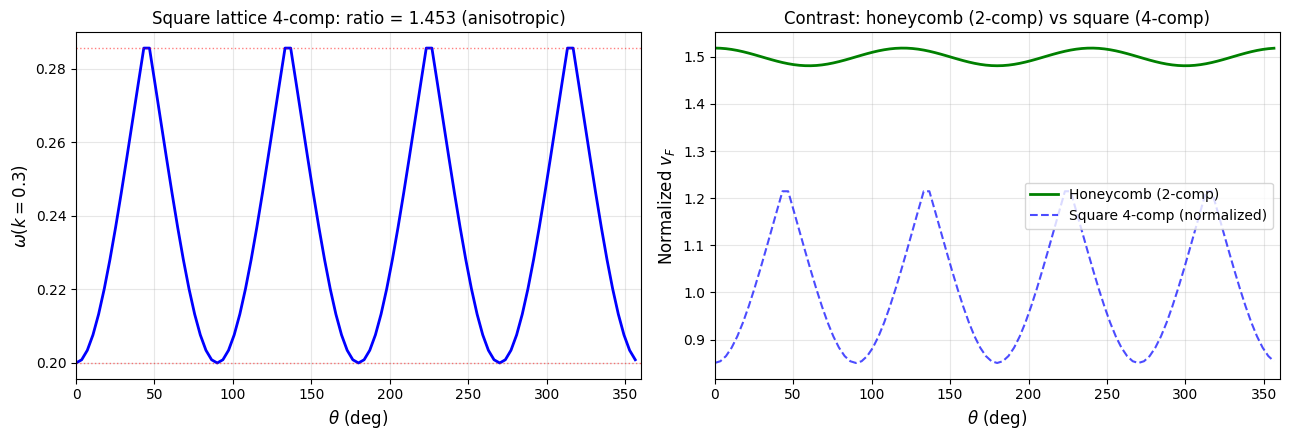

✅ Figure saved: 07_2d_square_fail.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Левая: дисперсия на квадратной решётке (4-comp) ---
thetas = np.linspace(0, 2*np.pi, 100, endpoint=False)
omegas_4 = [dispersion(0.3*np.cos(t), 0.3*np.sin(t), shifts_4_axis, C4) for t in thetas]

axes[0].plot(np.rad2deg(thetas), omegas_4, 'b-', lw=2)
axes[0].axhline(np.min(omegas_4), color='red', ls=':', lw=1, alpha=0.5)
axes[0].axhline(np.max(omegas_4), color='red', ls=':', lw=1, alpha=0.5)
axes[0].set_xlabel(r'$\theta$ (deg)', fontsize=12)
axes[0].set_ylabel(r'$\omega(k=0.3)$', fontsize=12)
axes[0].set_title(f'Square lattice 4-comp: ratio = {ratio_4:.3f} (anisotropic)',
                  fontsize=12)
axes[0].grid(alpha=0.3)
axes[0].set_xlim(0, 360)

# --- Правая: контраст с honeycomb (перенос из 06) ---
# Honeycomb: 2 компоненты, 3 направления
delta_honey = np.array([
    [0, 1],
    [np.sqrt(3)/2, -1/2],
    [-np.sqrt(3)/2, -1/2],
])
K_honey = np.array([2*np.pi/(3*np.sqrt(3)), 2*np.pi/3])

def f_honey(kx, ky):
    k = np.array([kx, ky])
    return np.sum(np.exp(1j * (delta_honey @ k)))

def omega_honey(kx, ky, m=0.001, tau=0.1):
    f = f_honey(kx, ky)
    H = np.array([[m, -f], [-np.conj(f), -m]])
    U = expm(-1j * H * tau)
    return np.abs(np.angle(np.linalg.eigvals(U))).min() / tau

# Дисперсия honeycomb по направлениям
omegas_honey = []
for t in thetas:
    q = 0.05
    qx, qy = q*np.cos(t), q*np.sin(t)
    omegas_honey.append(omega_honey(K_honey[0]+qx, K_honey[1]+qy) / q)

axes[1].plot(np.rad2deg(thetas), np.array(omegas_honey),
             'g-', lw=2, label='Honeycomb (2-comp)')
# Квадратная для сравнения (нормализуем)
omegas_4_norm = np.array(omegas_4) / np.mean(omegas_4)
axes[1].plot(np.rad2deg(thetas), omegas_4_norm,
             'b--', lw=1.5, alpha=0.7, label='Square 4-comp (normalized)')
axes[1].set_xlabel(r'$\theta$ (deg)', fontsize=12)
axes[1].set_ylabel('Normalized $v_F$', fontsize=12)
axes[1].set_title('Contrast: honeycomb (2-comp) vs square (4-comp)', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].set_xlim(0, 360)

plt.tight_layout()
plt.savefig('07_2d_square_fail.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Figure saved: 07_2d_square_fail.png")

In [9]:
from google.colab import files
files.download('07_2d_square_fail.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>